<a href="https://colab.research.google.com/github/saran-shams/Classic_CV/blob/main/HarrisCornerDectection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# LAB TASK 1:
def run_lab_task_1(image_path):
    print("--- Running Lab Task 1: Harris Corner Detection ---")

    img = cv2.imread('imag.jpeg')
    if img is None:
        raise FileNotFoundError(f"Could not load image at {image_path}")
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray_float = np.float32(gray)

    dst = cv2.cornerHarris(gray_float, blockSize=2, ksize=3, k=0.04)
    dst = cv2.dilate(dst, None)

    thresholds = [0.001, 0.01, 0.05]
    plt.figure(figsize=(15, 5))

    for i, thresh_val in enumerate(thresholds):
        img_thresh = img.copy()
        img_thresh[dst > thresh_val * dst.max()] = [0, 0, 255]

        plt.subplot(1, 3, i + 1)
        plt.imshow(cv2.cvtColor(img_thresh, cv2.COLOR_BGR2RGB))
        plt.title(f"Threshold: {thresh_val} * Max")
        plt.axis('off')
    plt.suptitle("Comparison of Different Harris Thresholds")
    plt.tight_layout()
    plt.show()

    h, w = gray.shape[:2]

    M_rot = cv2.getRotationMatrix2D((w // 2, h // 2), 45, 1.0)
    rotated_gray = cv2.warpAffine(gray, M_rot, (w, h))
    dst_rot = cv2.cornerHarris(np.float32(rotated_gray), blockSize=2, ksize=3, k=0.04)
    img_rot_vis = cv2.cvtColor(rotated_gray, cv2.COLOR_GRAY2RGB)
    img_rot_vis[dst_rot > 0.01 * dst_rot.max()] = [255, 0, 0]

    resized_gray = cv2.resize(gray, (int(w * 0.3), int(h * 0.3)), interpolation=cv2.INTER_AREA)
    dst_res = cv2.cornerHarris(np.float32(resized_gray), blockSize=2, ksize=3, k=0.04)
    img_res_vis = cv2.cvtColor(resized_gray, cv2.COLOR_GRAY2RGB)
    img_res_vis[dst_res > 0.01 * dst_res.max()] = [255, 0, 0]

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img_rot_vis)
    plt.title("Rotated Image Corners")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(img_res_vis)
    plt.title("Resized (Scaled Down) Corners")
    plt.axis('off')
    plt.tight_layout()
    plt.show()


# LAB TASK 2:
def run_lab_task_2(img1_path, img2_path):
    print("\n--- Running Lab Task 2: SIFT Panorama Stitching ---")

    img1 = cv2.imread('imag.jpeg')
    img2 = cv2.imread('i.jpeg')

    if img1 is None or img2 is None:
        raise FileNotFoundError("Verify path filenames for both overlapping images.")

    gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
    gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

    sift = cv2.SIFT_create()
    kp1, desc1 = sift.detectAndCompute(gray1, None)
    kp2, desc2 = sift.detectAndCompute(gray2, None)

    bf = cv2.BFMatcher()
    matches = bf.knnMatch(desc1, desc2, k=2)

    good_matches = []
    for m, n in matches:
        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

    print(f"Total passing matches after Lowe's ratio test: {len(good_matches)}")

    if len(good_matches) < 4:
        print("Not enough matching points found to compute a homography.")
        return

    src_pts = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

    H, status = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)

    inlier_count = np.sum(status)
    print(f"RANSAC Inlier Count: {inlier_count} out of {len(good_matches)} points")

    width = img1.shape[1] + img2.shape[1]
    height = max(img1.shape[0], img2.shape[0])
    panorama = cv2.warpPerspective(img1, H, (width, height))

    panorama[0:img2.shape[0], 0:img2.shape[1]] = img2

    gray_pano = cv2.cvtColor(panorama, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray_pano, 1, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    x, y, w, h = cv2.boundingRect(contours[0])
    cropped_panorama = panorama[y:y+h, x:x+w]

    plt.figure(figsize=(12, 6))
    plt.imshow(cv2.cvtColor(cropped_panorama, cv2.COLOR_BGR2RGB))
    plt.title("Stitched Panorama Result")
    plt.axis('off')
    plt.show()


--- Running Lab Task 1: Harris Corner Detection ---


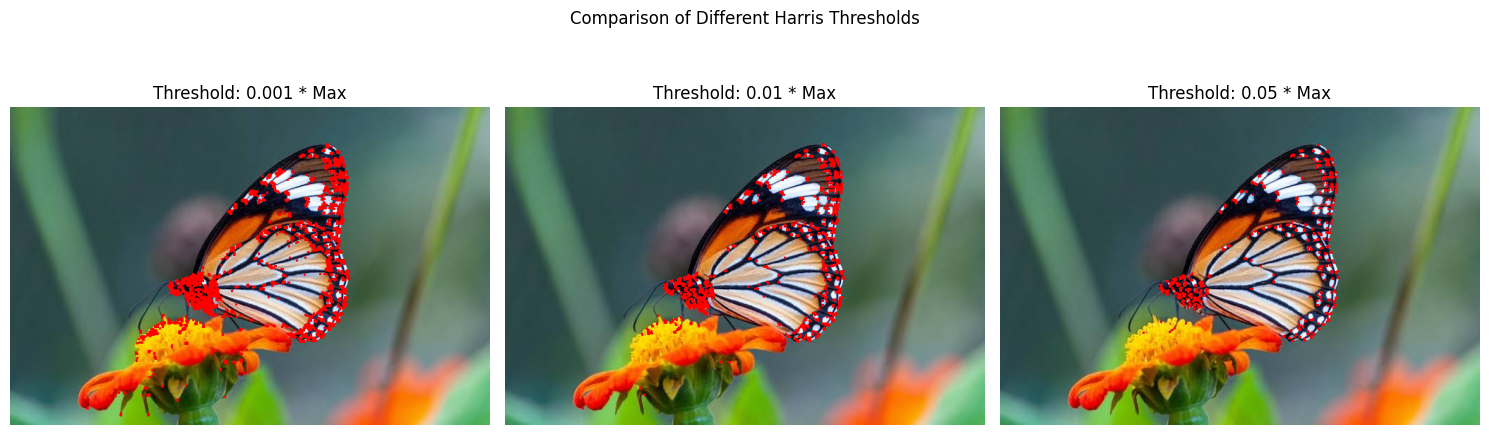

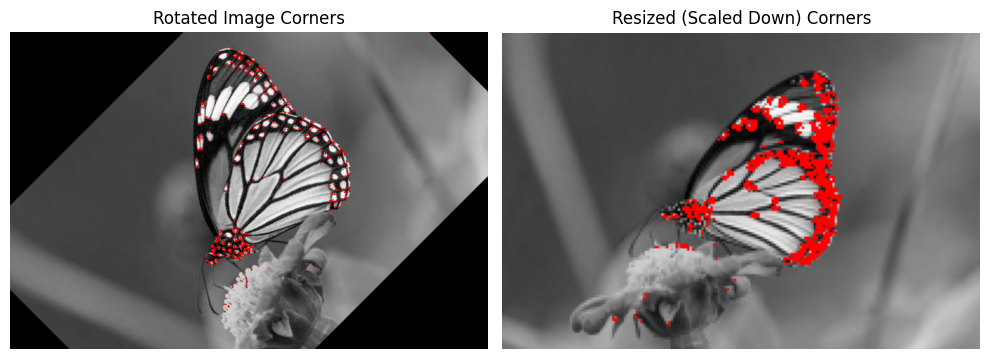


--- Running Lab Task 2: SIFT Panorama Stitching ---
Total passing matches after Lowe's ratio test: 38
✅ RANSAC Inlier Count: 12 out of 38 points


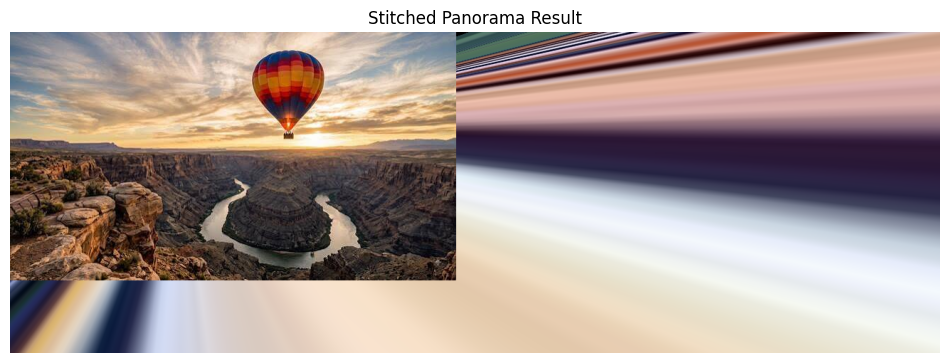

In [ ]:
run_lab_task_1('imag.jpeg')

run_lab_task_2('imag.jpeg', 'i.jpeg')